# 图 7-4　精英网络从星形网络到领结形网络的转型

对应书稿第七章图 7-4：王裕华 (2022) *The Rise and Fall of Imperial China* 第四章
Fig. 4.3（上排 abc）与 Fig. 4.4 前三面板（下排 def）的合并复现，整图无文字。

**上排 abc —— 精英社会地形（联姻亲属网络叠加地理坐标）**
- 节点 = 官员（深红）与其亲属（灰），位置取自作者原始经纬度（无底图），
  节点面积 ∝ 度中心性；
- 三个断面：晚唐 779–805、宋真宗 997–1022、宋神宗 1067–1085；
- 经纬度按 31°N 余弦拉伸，三面板共用地理窗口（东经 101–124.5，北纬 20.5–41.5）。

**下排 def —— 婚姻网络（节点 = 家族，连线 = 婚姻）**
- 晚唐 = Tackett 门阀婚姻网（邻接矩阵，134 个家族）；
- 宋代两帧 = 作者原码语义（官员行号被当作边编号抽取），与原书同口径；
- 经典 Fruchterman–Reingold 力导向布局（700 次迭代手写实现），
  节点大小 ∝ rescale(度数, 0.5, 3)，深灰实心圆仿原书黑白印刷。

**数据**：`output/wang2022-repro/raw/`（作者公开的复现数据，共 9 个文件）。

**输出**：`figures/fig7_4_elite_notebook.png`（13.2×9.4 in，210 dpi，
与书稿插图同规格）+ `results_fig7-4_combo.json`（两排全部结构统计）。

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

HERE = Path.cwd()
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)

# 显示用 110 dpi，保存用 210 dpi（13.2×9.4 in → 2772×1974 px，与书稿插图一致）
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 210
print("matplotlib", matplotlib.__version__, "| 数据目录", HERE)

/Users/socrates/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/socrates/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


matplotlib 3.4.3 | 数据目录 /Users/socrates/同步空间/Research/结构建模书稿章节/output/schich-repro


In [2]:
# ---------- 1. 上排公用：配色、地理窗口、数据构建 ----------

DARK, RED, GREY = "#2B2B2B", "#8B1A1A", "#7F7F7F"
PANEL_BG, EDGE_C = "#F7F7F4", "#C9C9C9"
LON0, LON1, LAT0, LAT1 = 101.0, 124.5, 20.5, 41.5     # 三面板共用地理窗口
ASPECT = 1 / np.cos(np.radians(31.0))                  # 31°N 余弦拉伸


def hav(lon1, lat1, lon2, lat2):
    """大圆距离（km）"""
    r = np.radians
    a = (np.sin((r(lat2) - r(lat1)) / 2) ** 2
         + np.cos(r(lat1)) * np.cos(r(lat2)) * np.sin((r(lon2) - r(lon1)) / 2) ** 2)
    return 2 * 6371.0088 * np.arcsin(np.sqrt(a))


CAPS = {"tang": [(108.907, 34.246), (112.45, 34.62)],   # 長安 / 洛陽
        "zhenzong": [(114.34, 34.79)],                  # 開封
        "shenzong": [(114.34, 34.79)]}


def build(edges_df, vert_df, idv, xo, yo, eo=None):
    """按顶点表裁边、建图、判官员节点、取坐标。返回 (G, pos, deg, is_ego, dropped)"""
    idset = set(vert_df[idv])
    keep = edges_df[edges_df.iloc[:, 0].isin(idset) & edges_df.iloc[:, 1].isin(idset)]
    dropped = len(edges_df) - len(keep)
    G = nx.Graph()
    G.add_nodes_from(vert_df[idv].tolist())
    G.add_edges_from(map(tuple, keep.values))
    deg = dict(G.degree())
    egos = set(edges_df.iloc[:, 0]) & idset if eo is None else set(
        vert_df.loc[vert_df[eo] == 1000, idv])
    pos = {r[idv]: (r[xo], r[yo]) for _, r in vert_df.iterrows()}
    is_ego = np.array([n in egos for n in G.nodes])
    return G, pos, deg, is_ego, dropped


MAP_PANELS = [   # (key, 边表规格, 顶点表规格, 边线宽, 边透明度) —— 与原脚本一致
    dict(key="tang", e=("tang edgelist.csv", None),
         v=("tang vertex.csv", "id", "X", "Y", "ego"), lw=0.5, ea=0.65),
    dict(key="zhenzong", e=("zhenzong officials and kin edgelist.csv", 0),
         v=("Zhenzong vertex attributes.csv", "c_personid", "x", "y", None),
         lw=0.22, ea=0.42),
    dict(key="shenzong", e=("shenzong officials and kin edgelist.csv", 0),
         v=("Shenzong vertex attributes.csv", "c_personid", "x", "y", None),
         lw=0.22, ea=0.42),
]
print("上排面板规格就绪：", [p["key"] for p in MAP_PANELS])

上排面板规格就绪： ['tang', 'zhenzong', 'shenzong']


In [3]:
# ---------- 2. 上排三断面：逐个建图并输出结构统计 ----------

TOP = {}
for P in MAP_PANELS:
    ef, hdr = P["e"]
    edges = pd.read_csv(ef, header=hdr,
                        names=["ego", "kin"] if hdr is None else None)
    vf, idv, xo, yo, eo = P["v"]
    vert = pd.read_csv(vf)
    G, pos, deg, is_ego, dropped = build(edges, vert, idv, xo, yo, eo)

    nodes = list(G.nodes)
    xs = np.array([pos[n][0] for n in nodes])
    ys = np.array([pos[n][1] for n in nodes])
    dd = np.array([deg[n] for n in nodes], float)

    n = G.number_of_nodes()
    comps = sorted(nx.connected_components(G), key=len, reverse=True)
    dens = nx.density(G)
    n_off = int(is_ego.sum())
    oxs, oys = xs[is_ego], ys[is_ego]
    Do = hav(oxs[:, None], oys[:, None], oxs[None, :], oys[None, :])
    iu = np.triu_indices(len(oxs), 1)
    d_mean = float(Do[iu].mean()) if len(oxs) > 1 else 0.0
    d_cap = np.min([hav(oxs, oys, cx, cy) for cx, cy in CAPS[P["key"]]], axis=0)
    cap_share = float((d_cap < 100).mean())
    print(f"[{P['key']:9s}] 节点 {n}（官员 {n_off}） 边 {G.number_of_edges()} "
          f"组件 {len(comps)} 最大 {len(comps[0])/n:.1%} 密度 {dens:.5f} "
          f"官员平均间距 {d_mean:.0f}km 都城100km内 {cap_share:.0%}")
    TOP[P["key"]] = dict(G=G, pos=pos, deg=deg, is_ego=is_ego, xs=xs, ys=ys, dd=dd,
                         stats=dict(n_nodes=n, n_officials=n_off,
                                    n_edges=int(G.number_of_edges()),
                                    n_components=len(comps),
                                    largest_share=round(len(comps[0]) / n, 4),
                                    density=round(dens, 6),
                                    official_spread_km=round(d_mean),
                                    capital_share_100km=round(cap_share, 3)))

[tang     ] 节点 458（官员 36） 边 422 组件 36 最大 14.0% 密度 0.00403 官员平均间距 345km 都城100km内 67%
[zhenzong ] 节点 1789（官员 88） 边 7183 组件 6 最大 98.8% 密度 0.00449 官员平均间距 465km 都城100km内 33%
[shenzong ] 节点 2106（官员 85） 边 7267 组件 8 最大 97.6% 密度 0.00328 官员平均间距 680km 都城100km内 26%


In [4]:
# ---------- 3. 下排数据：门阀婚姻网与宋代抽边 ----------

at = pd.read_csv("adjacency_matrix_tackett.csv",
                 header=None, lineterminator="\r")
At = at.values.astype(float)
np.fill_diagonal(At, 0)
G_tang = nx.from_numpy_array(At)

AS = pd.read_csv( "all song officials adj matrix.csv", header=None)
Asong = AS.values.astype(float)
np.fill_diagonal(Asong, 0)
NS = Asong.shape[0]
E_song = [(i, j) for i in range(NS) for j in range(i + 1, NS) if Asong[i, j]]
vs = pd.read_csv( "all song officials vertex attributes.csv")


def reign_net(k):
    """作者原码语义：eid = which(reign_k == 1) —— 官员行号被当作边编号"""
    ridx = np.where(vs[f"reign{k}"].values == 1)[0]
    return nx.Graph([E_song[e - 1] for e in (ridx + 1) if e <= len(E_song)])


print(f"Tackett 门阀网：{G_tang.number_of_nodes()} 节点 {G_tang.number_of_edges()} 边")
print(f"宋代邻接阵：{NS} 官员，上三角候选边 {len(E_song)} 条")

Tackett 门阀网：134 节点 252 边
宋代邻接阵：1904 官员，上三角候选边 7268 条


In [5]:
# ---------- 4. 下排布局：Fruchterman–Reingold 手写实现 ----------

def fr_core(G, seed, iters=700, k=None):
    """经典 FR 力导向（networkx 3.7 的 spring_layout 对非连通图不可用）"""
    nodes = list(G.nodes)
    n = len(nodes)
    A = nx.to_numpy_array(G, nodelist=nodes)
    rng = np.random.default_rng(seed)
    pos = rng.uniform(-1, 1, (n, 2))
    if k is None:
        k = 1.0 / np.sqrt(n)
    k2 = k * k
    t0 = 0.35
    for it in range(iters):
        diff = pos[:, None, :] - pos[None, :, :]
        dist = np.sqrt((diff ** 2).sum(-1)) + 1e-12
        unit = diff / dist[..., None]
        f = (k2 / dist)[..., None] * unit
        f += ((dist * dist / k)[..., None] * (-unit)) * A[..., None]
        disp = f.sum(1)
        dlen = np.sqrt((disp ** 2).sum(-1))
        t = t0 * (1 - it / iters)
        lim = np.minimum(dlen, t)
        pos += disp / np.maximum(dlen, 1e-12)[:, None] * lim[:, None]
    return {v: pos[i] for i, v in enumerate(nodes)}


def layout_book(G, seed, R=0.435, RMAX=0.492):
    """FR 布局 → 巨组件归一化到半径 R → 外围点截断/随机摊开（仿书版式）"""
    pos = fr_core(G, seed, k=2.2 / np.sqrt(G.number_of_nodes()))
    giant = max(nx.connected_components(G), key=len)
    gp = np.array([pos[v] for v in giant])
    c = gp.mean(0)
    r = np.sqrt(((gp - c) ** 2).sum(1)).max()
    s = R / max(r, 1e-9)
    rng = np.random.default_rng(seed + 1)
    out = {}
    for v, xy in pos.items():
        xy = (np.asarray(xy) - c) * s
        d = float(np.hypot(*xy))
        if d > RMAX:
            xy = xy / d * RMAX
        elif d > R * 1.15:
            xy = xy / d * (R * 1.15 + (RMAX - R * 1.15) * rng.uniform())
        out[v] = (0.5 + xy[0], 0.5 + xy[1])
    return out


def rescale_cex(deg, low=0.5, high=3.0):
    d = np.asarray(deg, float)
    if d.max() - d.min() < 1e-9:
        return np.full_like(d, (low + high) / 2)
    return (high - low) * (d - d.min()) / (d.max() - d.min()) + low


NODE_C = "#3A3A3A"
NET_PANELS = [   # (网络, 种子) —— 与原脚本一致
    (G_tang, 12349),
    (reign_net(3), 12346),
    (reign_net(6), 12347),
]
print("下排三个网络：", [(G.number_of_nodes(), G.number_of_edges()) for G, _ in NET_PANELS])

下排三个网络： [(134, 252), (192, 202), (209, 214)]


下排[tang     ] 节点 134 边 252 密度 0.02827965（原书 0.028） 组件 2
下排[zhenzong ] 节点 192 边 202 密度 0.01101658（原书 0.011） 组件 18
下排[shenzong ] 节点 209 边 214 密度 0.00984542（原书 0.01） 组件 19


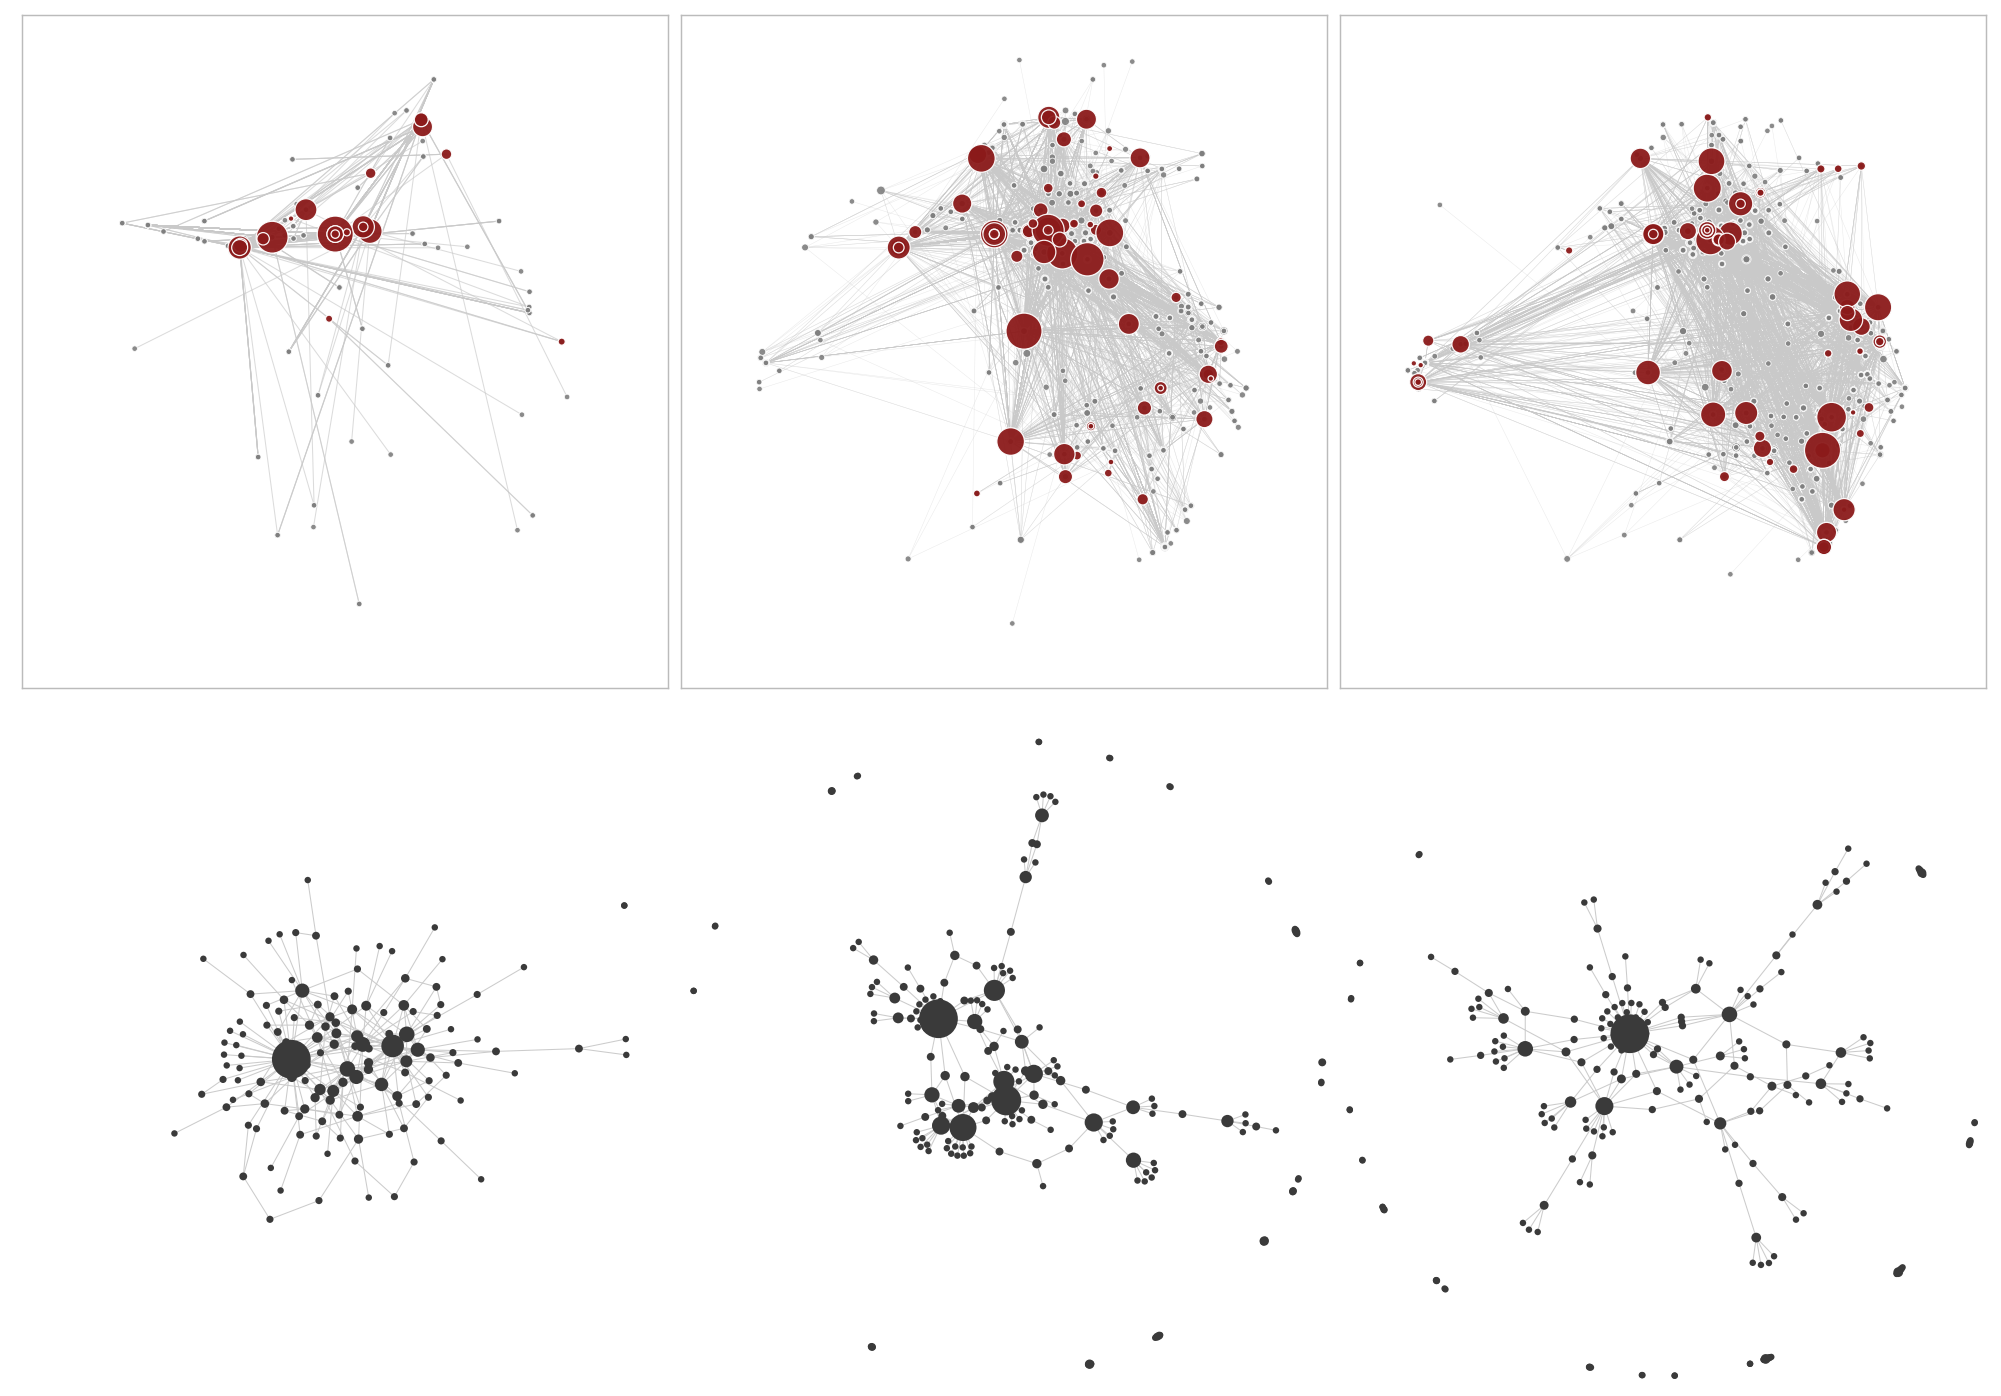

saved: /Users/socrates/同步空间/Research/结构建模书稿章节/output/schich-repro/figures/fig7_4_elite_notebook.pdf
saved results_fig7-4_combo.json


In [7]:
# ---------- 5. 绘制 2×3 合并图（整图无文字） ----------

fig = plt.figure(figsize=(13.2, 9.4), dpi = 150)
gs = fig.add_gridspec(2, 3, wspace=0.020, hspace=0.020,
                      left=0.004, right=0.996, top=0.996, bottom=0.004)
OUT = {"top_row": {}, "bottom_row": {}}

# ---------------------------------------------------------- 上排：地理坐标
for k, P in enumerate(MAP_PANELS):
    T = TOP[P["key"]]
    G, pos, dd, is_ego = T["G"], T["pos"], T["dd"], T["is_ego"]
    xs, ys = T["xs"], T["ys"]
    OUT["top_row"][P["key"]] = T["stats"]

    ax = fig.add_subplot(gs[0, k])
    ax.set_facecolor('white')          # 无底图；极浅底色保留白描边可读性
    segs = [(pos[u], pos[v]) for u, v in G.edges]
    ax.add_collection(LineCollection(segs, colors=EDGE_C, linewidths=P["lw"],
                                     alpha=P["ea"], zorder=2))
    lo, hi = 7, 300
    size = lo + (hi - lo) * (dd - dd.min()) / max(dd.max() - dd.min(), 1e-9)
    kin_m, off_m = ~is_ego, is_ego
    ax.scatter(xs[kin_m], ys[kin_m], s=size[kin_m], c=GREY, edgecolors="white",
               linewidths=0.4, alpha=0.9, zorder=3)
    ax.scatter(xs[off_m], ys[off_m], s=size[off_m], c=RED, edgecolors="white",
               linewidths=0.6, alpha=0.95, zorder=4)
    ax.set_xlim(LON0, LON1)
    ax.set_ylim(LAT0, LAT1)
    ax.set_aspect(ASPECT)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
    for sp in ax.spines.values():
        sp.set_edgecolor("#BBBBBB"); sp.set_linewidth(0.7)

# ---------------------------------------------------------- 下排：力导向
for k, (G, seed) in enumerate(NET_PANELS):
    ax = fig.add_subplot(gs[1, k])
    deg = dict(G.degree())
    pos = layout_book(G, seed)
    comps = sorted(nx.connected_components(G), key=len, reverse=True)
    dens = nx.density(G)
    for u, v in G.edges():
        ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]],
                color=EDGE_C, lw=0.5, alpha=0.95, zorder=1, solid_capstyle="round")
    cex = rescale_cex([deg[n] for n in G.nodes])
    ax.scatter([pos[n][0] for n in G.nodes], [pos[n][1] for n in G.nodes],
               s=(cex * 6.2) ** 2, c=NODE_C, linewidths=0, alpha=1.0, zorder=2)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    key = ["tang", "zhenzong", "shenzong"][k]
    book_d = {0: 0.028, 1: 0.011, 2: 0.010}[k]      # 原书报告值
    print(f"下排[{key:9s}] 节点 {G.number_of_nodes()} 边 {G.number_of_edges()} "
          f"密度 {dens:.8f}（原书 {book_d}） 组件 {len(comps)}")
    OUT["bottom_row"][key] = dict(n=G.number_of_nodes(), e=G.number_of_edges(),
                                  density=round(dens, 8), n_components=len(comps),
                                  book_density=book_d)

plt.show()

out_png = FIG / "fig7_4_elite_notebook.pdf"
fig.savefig(out_png, facecolor="white", bbox_inches=None)
print("saved:", out_png)
json.dump(OUT, open(HERE / "results_fig7-4_combo.json", "w", encoding="utf-8"),
          ensure_ascii=False, indent=1)
print("saved results_fig7-4_combo.json")